<h1><center>Генерация текстов с помощью LSTM

<h2>Загрузка и преобработка данных</h2>


Для автоматического обучения модели, скачали библиотеку lightning, являющуюся wrapper-ом.

In [4]:
import warnings
import pytorch_lightning as pl
import torch
from torch import nn

warnings.filterwarnings('ignore')

W0729 12:02:15.319000 424 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


<h3>Подготовка данных

In [ ]:
# import urllib.request

# url = "https://www.gutenberg.org/cache/epub/1399/pg1399.txt"

# with urllib.request.urlopen(url) as response:
#     raw_text = response.read().decode('utf-8')

# start_idx = raw_text.find("Chapter 1")
# end_idx = raw_text.rfind("*** END OF THE PROJECT GUTENBERG EBOOK")
# clean_text = raw_text[start_idx:end_idx].strip()

# prepared_text = clean_text.replace('\r\n', '\n')

# prepared_text =  prepared_text

# print(repr(prepared_text[:200]))

# with open("anna_karenina_raw.txt", "w", encoding="utf-8") as f:
#     f.write(prepared_text)

'Chapter 1\n\n\nHappy families are all alike; every unhappy family is unhappy in its\nown way.\n\nEverything was in confusion in the Oblonskys’ house. The wife had\ndiscovered that the husband was carrying on'


<_io.TextIOWrapper name='anna_karenina_raw.txt' mode='w' encoding='utf-8'>

In [5]:
with open('anna_karenina_raw.txt', 'r', encoding='utf8') as f:
    text = f.read()


text[:200]

'Chapter 1\n\n\nHappy families are all alike; every unhappy family is unhappy in its\nown way.\n\nEverything was in confusion in the Oblonskys’ house. The wife had\ndiscovered that the husband was carrying on'

<h3>Токенизация данных

In [6]:
unique_chars = tuple(set(text))
int2char = dict(enumerate(unique_chars))
char2int = {ch: ii for ii, ch in int2char.items()}

encoded = torch.tensor([char2int[char] for char in text])
encoded[:100]

tensor([89, 50, 65, 44, 25, 20, 55, 42, 24, 74, 74, 74, 51, 65, 44, 44, 27, 42,
        56, 65, 14, 86, 52, 86, 20, 82, 42, 65, 55, 20, 42, 65, 52, 52, 42, 65,
        52, 86,  8, 20, 83, 42, 20, 71, 20, 55, 27, 42, 64, 53, 50, 65, 44, 44,
        27, 42, 56, 65, 14, 86, 52, 27, 42, 86, 82, 42, 64, 53, 50, 65, 44, 44,
        27, 42, 86, 53, 42, 86, 25, 82, 74, 13, 41, 53, 42, 41, 65, 27, 81, 74,
        74, 37, 71, 20, 55, 27, 25, 50, 86, 53])

In [7]:
def one_hot_encode(int_words, n_labels):
    words_one_hot = torch.zeros((int_words.numel(), n_labels), dtype=
                                torch.float32, device=int_words.device)
    words_one_hot[torch.arange(words_one_hot.shape[0]), int_words.flatten()] = 1.0
    words_one_hot = words_one_hot.reshape((*int_words.shape, n_labels))
    return words_one_hot


test_seq = torch.tensor([[3, 5, 1], [0, 2, 4]])
test_one_hot = one_hot_encode(test_seq, 8)

print(test_one_hot)

tensor([[[0., 0., 0., 1., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0., 1., 0., 0.],
         [0., 1., 0., 0., 0., 0., 0., 0.]],

        [[1., 0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 1., 0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 1., 0., 0., 0.]]])


<h3>Формирование батчей

In [21]:
def get_batches(int_words, batch_size, seq_length):
    window_size = seq_length + 1
    batch_size_total = batch_size * window_size
    n_bathces = len(int_words) // batch_size_total
    int_words = int_words[: n_bathces * batch_size_total]

    int_words = int_words.reshape((batch_size, -1))

    for position in range(0, int_words.shape[1], window_size):
        x = int_words[:, position : position + window_size - 1]
        y = int_words[:, position + 1 : position + window_size]
        yield x, y

test_batches = get_batches(encoded, 8, 50)
test_x, test_y = next(test_batches)
assert test_x.shape == test_y.shape
print(f'x:\n{test_x[:10, :10]}\n')
print(f'y:\n{test_y[:10, :10]}\n')
print(f'e:\n{encoded}')


x:
tensor([[89, 50, 65, 44, 25, 20, 55, 42, 24, 74],
        [20, 36, 42, 25, 50, 20, 42, 36, 13, 13],
        [ 0, 26, 42, 77, 13, 53, 77, 52, 64, 36],
        [64, 86, 25, 20, 42, 56, 55, 20, 20, 42],
        [86, 82, 50, 20, 36, 42, 56, 55, 13, 14],
        [42, 65, 52, 13, 53, 20,  0, 74, 44, 64],
        [81, 42,  5, 78, 53, 52, 27, 74, 27, 20],
        [13, 25, 50, 20, 55, 42, 41, 65, 82, 42]])

y:
tensor([[50, 65, 44, 25, 20, 55, 42, 24, 74, 74],
        [36, 42, 25, 50, 20, 42, 36, 13, 13, 55],
        [26, 42, 77, 13, 53, 77, 52, 64, 36, 20],
        [86, 25, 20, 42, 56, 55, 20, 20, 42, 56],
        [82, 50, 20, 36, 42, 56, 55, 13, 14, 42],
        [65, 52, 13, 53, 20,  0, 74, 44, 64, 25],
        [42,  5, 78, 53, 52, 27, 74, 27, 20, 82],
        [25, 50, 20, 55, 42, 41, 65, 82, 42, 86]])

e:
tensor([89, 50, 65,  ..., 25, 81, 26])


<h2>Формируем класс набора данных

In [22]:
class AnnData(torch.utils.data.IterableDataset):
    def __init__(self, int_words, batch_size, seq_length):
        self.int_words = int_words
        self.batch_size = batch_size
        self.seq_length = seq_length

    def __iter__(self):
        return get_batches(self.int_words, self.batch_size, self.seq_length)

<h2>Проектирование и обучение модели</h2>

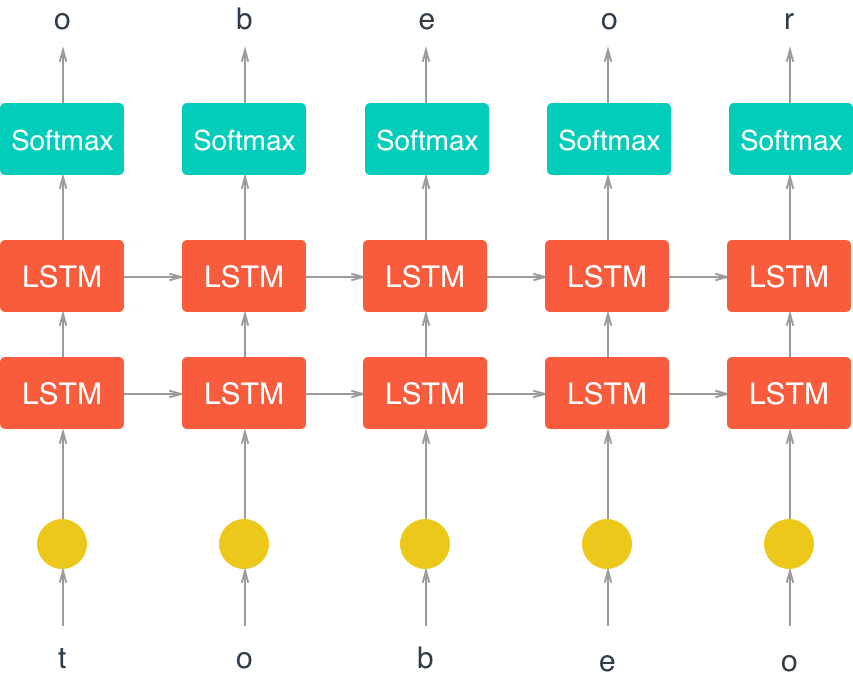

<h3>Структура модели

In [26]:
class CharRNN(nn.Module):
    def __init__(self, unique_tokens, n_hidden=256, n_layers=2, drop_prob=.3):
        super(CharRNN, self).__init__()
        self.n_hidden = n_hidden
        self.n_layers = n_layers
        self.drop_prod = drop_prob

        self.unique_tokens = unique_tokens
        self.int2char = dict(enumerate(self.unique_tokens))
        self.char2int = {ch : ii for ii, ch in self.int2char.items()}

        self.lstm = nn.LSTM(len(unique_tokens), n_hidden, n_layers,
                            dropout=drop_prob, batch_first=True)
        self.dropout = nn.Dropout(drop_prob)
        self.fc = nn.Linear(n_hidden, len(unique_tokens))

    def forward(self, x, hidden):
        r_output, hidden = self.lstm(x, hidden)
        out = self.dropout(r_output)
        out = out.contiguous().view(-1, self.n_hidden)
        out = self.fc(out)
        return out, hidden
    
    def init_hidden(self, batch_size, weight_device):
        weight = next(self.parameters()).data
        hidden = (
            weight.new(self.n_layers, batch_size, self.n_hidden).zero_().to(weight_device),
            weight.new(self.n_layers, batch_size, self.n_hidden).zero_().to(weight_device),
        )
        return hidden
    
class CharRNNModule(pl.LightningModule):
    def __init__(self, unique_tokens, n_hidden=1024, n_layers=2, drop_prob=.5,
                 batch_size=128, seq_length=256, lr=.001):
        super(CharRNNModule, self).__init__()
        self.model = CharRNN(unique_tokens, n_hidden, n_layers, drop_prob)
        self.hidden = None
        self.loss = nn.CrossEntropyLoss()
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=lr)
        self.n_chars = len(unique_tokens)
        self.batch_size = batch_size
        self.seq_length = seq_length

    def training_step(self, train_batch):
        x, y = train_batch
        x, y = x.squeeze(0), y.squeeze(0)
        x = one_hot_encode(x, self.n_chars)

        if self.hidden is None:
            self.hidden = self.model.init_hidden(self.batch_size, self.device)
        self.hidden = tuple([each.data for each in self.hidden])

        output, self.hidden = self.model(x, self.hidden)
        loss = self.loss(output, y.reshape(self.batch_size * self.seq_length))

        self.log('train_loss', loss, prog_bar=True)
        return loss
    
    def configure_optimizers(self):
        return self.optimizer

<h2>Обучение модели

In [28]:
train_dataset = AnnData(encoded, batch_size=128, seq_length=256)

train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size=1,
                                               shuffle=False)

char_rnn = CharRNNModule(unique_chars, n_hidden=1024, batch_size=128)
trainer = pl.Trainer(max_epochs=15, gradient_clip_val=1.0, accelerator='gpu',
                     devices=1)
trainer.fit(char_rnn, train_dataloader)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ CharRNN          │ 13.1 M │ train │     0 │
│ 1 │ loss  │ CrossEntropyLoss │      0 │ train │     0 │
└───┴───────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 13.1 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 13.1 M                                                                                               
Total estimated model params size (MB): 52.323                                                                     
Modules in train mode: 5                                                                                           
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_epochs=15` reached.


<h2>Инференс модели

In [49]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

@torch.inference_mode()
def predict_next_char(model, char, h, top_k):
    x = torch.tensor([[model.char2int[char]]])
    x = one_hot_encode(x, len(model.unique_tokens))
    x = x.to(device)

    h = tuple([each.data for each in h])

    out, h = model(x, h)

    p = torch.nn.functional.softmax(out, dim=1).data.cpu()

    if top_k is None:
        top_ch = torch.arange(len(model.unique_tokens))
    else:
        p, top_ch = p.topk(top_k)

    p.squeeze_()
    top_ch.squeeze_()
    char = top_ch[torch.multinomial(p / p.sum(),  1)]

    return model.int2char[char.item()], h

def sample(model, size, prime='The', top_k=None):
    model.to(device)
    model.eval()

    chars = [ch for ch in prime]
    h = model.init_hidden(1, device)
    for ch in prime:
        char, h = predict_next_char(model, ch, h, top_k=top_k)
    
    chars.append(char)

    for ii in range(size):
        char, h = predict_next_char(model, chars[-1], h, top_k=top_k)
        chars.append(char)

    return ''.join(chars)


Device: cuda


In [52]:
print(sample(char_rnn.model, 1000, prime='Anna sit on the chair', top_k=5))

Anna sit on the chair ao no tetate the tot one wor ter tot ohe aor tot ateatiane toe ahes she te sos anere an iod ane tor sas ao hhis thet teee ao aon tied harit eosat tote toe toe the tee atit tie tas tinnte heterorer the wanest hit the ahe wat ahe tos hares tatithete hor and whe shere he tirariat te hierane heras he hetitise the titot hir th ther hor tathe the site hes ao ser so nha to te tas sasan the thes toe tose sirot oo see we atotondee aond set toretees aaserat io tansitot an tot oher to heree
tee hee te thetiare wat to hise het aatharo tote hhe toed wostonnitintat the te wote teeer ter aho th teree
wararise ses tose sat aon tis he win atose he te hat ane ahith ta sh aod tor tint to titit an tet tiens tetea tee wo nothir oneee hhe ah thee hint ther heteanna sere saer shonte tor ther atot to toer aot one ter onrannt ohinit an aa sera te tertot aora toere ter tore ao terirat io nis to she wire hhe soret tote ho se ahes hin sane ho hore whes anrase sh it iteatoras the the and tara